[![Abrir en Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/DANIFUZZY1975/estadistica-descriptiva-python/blob/main/notebooks/02_felicidad_mundial.ipynb)

# 😊 ¿Dónde se vive más feliz? Estadística descriptiva con el *World Happiness Report 2021*

**Estadística Descriptiva · 1.º Grado en Ciencia de Datos · UCM**

Cada fila es un **país** (149). La variable estrella es el **Ladder score**: la puntuación media (0–10)
que dan los habitantes a la pregunta *"imagina una escalera donde 10 es la mejor vida posible y 0 la peor: ¿en qué peldaño estás?"*.

En este notebook vamos a responder preguntas como:
- ¿Cuál es el país "típico"? ¿Media o mediana?
- ¿Qué región del mundo es más feliz… y cuál es más **desigual**?
- ¿Hay países **anómalos**? (felices siendo pobres, o infelices siendo ricos)
- ¿Dónde está **España**?

> 💡 Ejecuta las celdas en orden (`Shift + Enter`). Donde veas **🤔**, para y piensa antes de seguir.

In [1]:
# ============================================================
# 0. Librerías, estilo y funciones de apoyo
# ============================================================
import os
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats

pd.set_option("display.max_columns", None)
pd.set_option("display.float_format", lambda v: f"{v:,.3f}")

sns.set_theme(style="whitegrid", context="notebook")
AZUL, NARANJA, VERDE, AMARILLO = "#2a78d6", "#eb6834", "#1baf7a", "#eda100"
plt.rcParams.update({"figure.figsize": (10, 4), "axes.titleweight": "bold"})

# Los datos se leen del repositorio de GitHub, así el notebook funciona
# igual en Colab, en Jupyter local o en VS Code sin subir nada a mano.
URL_DATOS = "https://raw.githubusercontent.com/DANIFUZZY1975/estadistica-descriptiva-python/main/data/"

def cargar(nombre, **kwargs):
    """Busca el CSV en local (../data o carpeta actual); si no está, lo baja de GitHub."""
    for ruta in (os.path.join("..", "data", nombre), os.path.join("data", nombre), nombre):
        if os.path.exists(ruta):
            return pd.read_csv(ruta, **kwargs)
    return pd.read_csv(URL_DATOS + nombre, **kwargs)


def moda(x):
    """Moda 'honesta':
    - variable discreta (pocos valores distintos) -> valor más repetido;
    - variable continua -> punto medio de la CLASE modal del histograma (Sturges),
      porque en una continua casi ningún valor se repite y x.mode() no tiene sentido."""
    x = pd.Series(x).dropna()
    if x.nunique() <= 30:
        return x.mode().iloc[0]
    frec, bordes = np.histogram(x, bins="sturges")
    i = frec.argmax()
    return (bordes[i] + bordes[i + 1]) / 2


def limites_tukey(x, k=1.5):
    """Vallas de Tukey: [Q1 - k·RIC , Q3 + k·RIC] (las del diagrama de caja)."""
    q1, q3 = np.nanquantile(x, [0.25, 0.75])
    ric = q3 - q1
    return q1 - k * ric, q3 + k * ric


def resumen(x):
    """Todas las medidas descriptivas de una variable cuantitativa en una Serie."""
    x = pd.Series(x).dropna().astype(float)
    q1, me, q3 = x.quantile([0.25, 0.50, 0.75])
    li, ls = limites_tukey(x)
    return pd.Series({
        # --- tamaño
        "n": x.size,
        # --- medidas de posición central
        "media": x.mean(),
        "mediana": me,
        "moda": moda(x),
        "media_recortada_5%": stats.trim_mean(x, 0.05),  # quita el 5 % de CADA cola
        # --- medidas de posición no central
        "min": x.min(), "Q1": q1, "Q3": q3, "max": x.max(),
        # --- medidas de dispersión
        "rango": x.max() - x.min(),
        "RIC": q3 - q1,
        "varianza": x.var(),          # cuasivarianza (divide entre n-1)
        "desv_tipica": x.std(),       # cuasidesviación típica (n-1)
        "CV_%": 100 * x.std() / abs(x.mean()) if x.mean() != 0 else np.nan,
        "MAD": stats.median_abs_deviation(x),  # mediana de |x - mediana|
        # --- medidas de forma
        "asimetria_Fisher": x.skew(),
        "asimetria_Pearson": 3 * (x.mean() - me) / x.std(),
        "curtosis_exceso": x.kurt(),  # 0 = como la normal
        # --- anómalos
        "n_atipicos_Tukey": int(((x < li) | (x > ls)).sum()),
    })


def histograma_con_centros(x, titulo="", bins="auto", ax=None, color=AZUL):
    """Histograma + KDE con media, mediana y moda marcadas."""
    x = pd.Series(x).dropna()
    ax = ax or plt.gca()
    sns.histplot(x, bins=bins, kde=True, color=color, alpha=0.35, ax=ax)
    for valor, etiqueta, estilo in [(x.mean(), "media", "-"),
                                    (x.median(), "mediana", "--"),
                                    (moda(x), "moda", ":")]:
        ax.axvline(valor, color="#333333", ls=estilo, lw=2,
                   label=f"{etiqueta} = {valor:,.2f}")
    ax.set_title(titulo or x.name)
    ax.legend(frameon=False)
    return ax

## 1. Cargamos y miramos los datos
Antes de calcular nada: **¿cuántas filas, qué columnas, de qué tipo, hay huecos?**

In [2]:
df = cargar("world-happiness-report-2021.csv")
print("Dimensiones:", df.shape)
df.head()

Dimensiones: (149, 20)


,Country name,Regional indicator,Ladder score,Standard error of ladder score,upperwhisker,lowerwhisker,Logged GDP per capita,Social support,Healthy life expectancy,Freedom to make life choices,Generosity,Perceptions of corruption,Ladder score in Dystopia,Explained by: Log GDP per capita,Explained by: Social support,Explained by: Healthy life expectancy,Explained by: Freedom to make life choices,Explained by: Generosity,Explained by: Perceptions of corruption,Dystopia + residual
0,Finland,Western Europe,7.842,0.032,7.904,7.780,10.775,0.954,72.000,0.949,-0.098,0.186,2.430,1.446,1.106,0.741,0.691,0.124,0.481,3.253
1,Denmark,Western Europe,7.620,0.035,7.687,7.552,10.933,0.954,72.700,0.946,0.030,0.179,2.430,1.502,1.108,0.763,0.686,0.208,0.485,2.868
2,Switzerland,Western Europe,7.571,0.036,7.643,7.500,11.117,0.942,74.400,0.919,0.025,0.292,2.430,1.566,1.079,0.816,0.653,0.204,0.413,2.839
3,Iceland,Western Europe,7.554,0.059,7.670,7.438,10.878,0.983,73.000,0.955,0.160,0.673,2.430,1.482,1.172,0.772,0.698,0.293,0.170,2.967
4,Netherlands,Western Europe,7.464,0.027,7.518,7.410,10.932,0.942,72.400,0.913,0.175,0.338,2.430,1.501,1.079,0.753,0.647,0.302,0.384,2.798


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 149 entries, 0 to 148
Data columns (total 20 columns):
 #   Column                                      Non-Null Count  Dtype  
---  ------                                      --------------  -----  
 0   Country name                                149 non-null    str    
 1   Regional indicator                          149 non-null    str    
 2   Ladder score                                149 non-null    float64
 3   Standard error of ladder score              149 non-null    float64
 4   upperwhisker                                149 non-null    float64
 5   lowerwhisker                                149 non-null    float64
 6   Logged GDP per capita                       149 non-null    float64
 7   Social support                              149 non-null    float64
 8   Healthy life expectancy                     149 non-null    float64
 9   Freedom to make life choices                149 non-null    float64
 10  Generosity               

Las columnas `Explained by: ...`, `upperwhisker`, `lowerwhisker`, `Dystopia...` son resultados de un modelo de los autores.
Nos quedamos con las variables "en bruto" y les ponemos nombres cortos en castellano.

In [4]:
df = df.rename(columns={
    "Country name": "pais", "Regional indicator": "region", "Ladder score": "felicidad",
    "Logged GDP per capita": "log_PIB", "Social support": "apoyo_social",
    "Healthy life expectancy": "esperanza_vida", "Freedom to make life choices": "libertad",
    "Generosity": "generosidad", "Perceptions of corruption": "corrupcion",
})[["pais", "region", "felicidad", "log_PIB", "apoyo_social", "esperanza_vida",
    "libertad", "generosidad", "corrupcion"]]

# El PIB viene en logaritmo: recuperamos el PIB per cápita en dólares para ver la diferencia
df["PIB_pc"] = np.exp(df["log_PIB"])
cuantitativas = ["felicidad", "PIB_pc", "log_PIB", "apoyo_social", "esperanza_vida",
                 "libertad", "generosidad", "corrupcion"]
df.head()

,pais,region,felicidad,log_PIB,apoyo_social,esperanza_vida,libertad,generosidad,corrupcion,PIB_pc
0,Finland,Western Europe,7.842,10.775,0.954,72.000,0.949,-0.098,0.186,"47,810.473"
1,Denmark,Western Europe,7.620,10.933,0.954,72.700,0.946,0.030,0.179,"55,994.010"
2,Switzerland,Western Europe,7.571,11.117,0.942,74.400,0.919,0.025,0.292,"67,305.686"
3,Iceland,Western Europe,7.554,10.878,0.983,73.000,0.955,0.160,0.673,"52,997.499"
4,Netherlands,Western Europe,7.464,10.932,0.942,72.400,0.913,0.175,0.338,"55,938.044"


### Tipos de variables
| Variable | Tipo |
|---|---|
| `pais` | cualitativa nominal (identificador) |
| `region` | cualitativa nominal |
| `felicidad`, `PIB_pc`, `esperanza_vida`… | cuantitativas continuas |

🤔 *¿Tiene sentido calcular la "media" de `region`? ¿Y su moda?*

## 2. Variable cualitativa: tabla de frecuencias de `region`

In [5]:
frec = df["region"].value_counts().to_frame("n_i")
frec["f_i"] = frec["n_i"] / frec["n_i"].sum()
frec["N_i"] = frec["n_i"].cumsum()
frec["F_i"] = frec["f_i"].cumsum()
frec

,n_i,f_i,N_i,F_i
region,,,,
Sub-Saharan Africa,36,0.242,36,0.242
Western Europe,21,0.141,57,0.383
Latin America and Caribbean,20,0.134,77,0.517
Middle East and North Africa,17,0.114,94,0.631
Central and Eastern Europe,17,0.114,111,0.745
Commonwealth of Independent States,12,0.081,123,0.826
Southeast Asia,9,0.060,132,0.886
South Asia,7,0.047,139,0.933
East Asia,6,0.040,145,0.973


Las frecuencias acumuladas `N_i` y `F_i` aquí se pueden calcular… pero **no significan nada**,
porque las regiones no tienen un orden natural. Solo tienen sentido en variables **ordinales** o cuantitativas.

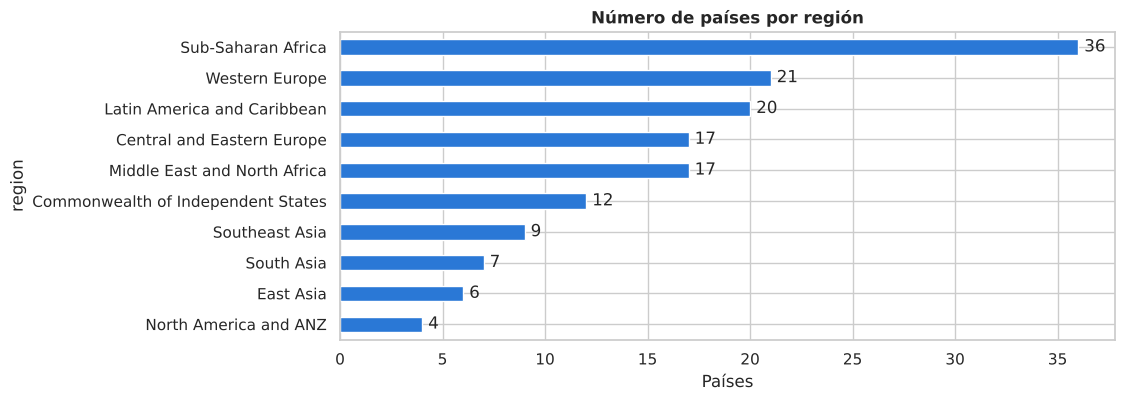

Moda de region: Sub-Saharan Africa


In [6]:
ax = df["region"].value_counts(ascending=True).plot.barh(color=AZUL)
ax.set_title("Número de países por región")
ax.set_xlabel("Países")
for i, v in enumerate(df["region"].value_counts(ascending=True)):
    ax.text(v + 0.3, i, str(v), va="center")
plt.show()
print("Moda de region:", df["region"].mode()[0])

## 3. Medidas de posición: ¿cuál es el país "típico"?

In [7]:
x = df["felicidad"]
print(f"Media              : {x.mean():.3f}")
print(f"Mediana            : {x.median():.3f}")
print(f"Moda (x.mode())    : {x.mode().tolist()[:5]} ...  ({x.mode().size} valores!)")
print(f"Moda (clase modal) : {moda(x):.3f}")
print(f"Media recortada 5% : {stats.trim_mean(x, 0.05):.3f}")

Media              : 5.533
Mediana            : 5.534
Moda (x.mode())    : [5.477, 5.929] ...  (2 valores!)
Moda (clase modal) : 5.182
Media recortada 5% : 5.543


🤔 **¿Por qué `x.mode()` da dos valores raros?** En una variable continua casi ningún valor se repite: aquí solo
coinciden por casualidad dos parejas de países (Rusia y Hong Kong con 5.477; Argentina y Portugal con 5.929).
Eso no describe "el valor más habitual". Para continuas usamos la **clase modal**
(el intervalo del histograma con más observaciones).

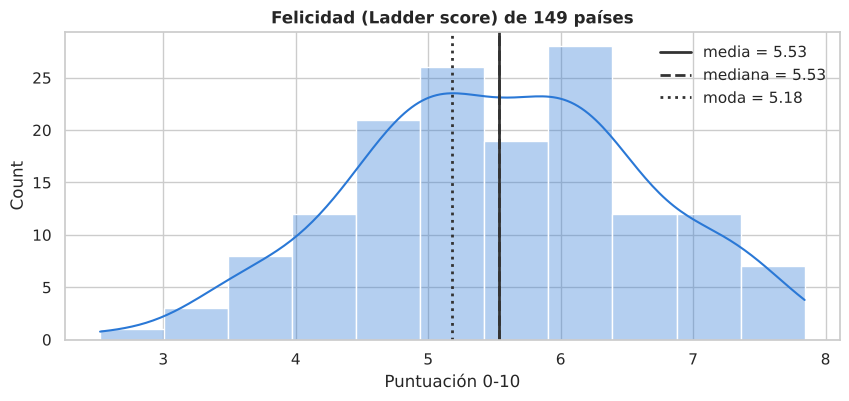

In [8]:
histograma_con_centros(df["felicidad"], "Felicidad (Ladder score) de 149 países")
plt.xlabel("Puntuación 0-10"); plt.show()

### Cuantiles, deciles y percentiles

In [9]:
print(df["felicidad"].quantile([0.10, 0.25, 0.50, 0.75, 0.90]).round(3))

0.100   4.223
0.250   4.852
0.500   5.534
0.750   6.255
0.900   7.072
Name: felicidad, dtype: float64


### ¿Y España? Posición relativa: percentil y puntuación tipificada (z)
$$ z = \frac{x - \bar x}{s} $$
z indica **a cuántas desviaciones típicas** de la media está un país. Sirve para comparar variables con unidades distintas.

In [10]:
def ficha_pais(nombre):
    fila = df.loc[df["pais"] == nombre].iloc[0]
    tabla = []
    for v in ["felicidad", "PIB_pc", "apoyo_social", "esperanza_vida", "libertad", "generosidad", "corrupcion"]:
        z = (fila[v] - df[v].mean()) / df[v].std()
        pct = stats.percentileofscore(df[v], fila[v])
        tabla.append({"variable": v, "valor": fila[v], "z": z, "percentil": pct})
    return pd.DataFrame(tabla).set_index("variable")

ficha_pais("Spain")

,valor,z,percentil
variable,,,
felicidad,6.491,0.892,82.550
PIB_pc,"38,987.642",0.833,78.523
apoyo_social,0.932,1.021,84.564
esperanza_vida,74.700,1.436,97.987
libertad,0.761,-0.270,37.584
generosidad,-0.081,-0.437,38.255
corrupcion,0.745,0.098,41.275


🤔 España está en el percentil 98 de esperanza de vida… pero por debajo de la mitad en libertad percibida. Prueba con tu país favorito:
`ficha_pais("Finland")`, `ficha_pais("Mexico")`, `ficha_pais("Japan")`...

## 4. Medidas de dispersión: ¿son los países parecidos entre sí?

In [11]:
x = df["felicidad"]
print(f"Rango                 : {x.max() - x.min():.3f}  ({df.loc[x.idxmin(), 'pais']} → {df.loc[x.idxmax(), 'pais']})")
print(f"Rango intercuartílico : {x.quantile(.75) - x.quantile(.25):.3f}")
print(f"Varianza  (n-1)       : {x.var():.3f}     | numpy por defecto (n): {np.var(x):.3f}")
print(f"Desv. típica (n-1)    : {x.std():.3f}     | numpy por defecto (n): {np.std(x):.3f}")
print(f"Coef. de variación    : {100 * x.std() / x.mean():.1f} %")
print(f"MAD                   : {stats.median_abs_deviation(x):.3f}")

Rango                 : 5.319  (Afghanistan → Finland)
Rango intercuartílico : 1.403
Varianza  (n-1)       : 1.153     | numpy por defecto (n): 1.146
Desv. típica (n-1)    : 1.074     | numpy por defecto (n): 1.070
Coef. de variación    : 19.4 %
MAD                   : 0.700


⚠️ **Trampa clásica:** `pandas` divide entre $n-1$ (cuasivarianza) y `numpy` entre $n$. Con 149 datos la diferencia es pequeña;
con 5 datos no. Mirad siempre qué fórmula usa la función.

### Coeficiente de variación: comparar dispersión de variables con unidades distintas
¿Qué varía más entre países: el **PIB** (dólares) o la **esperanza de vida** (años)? Comparar desviaciones típicas no tiene sentido; el CV sí.

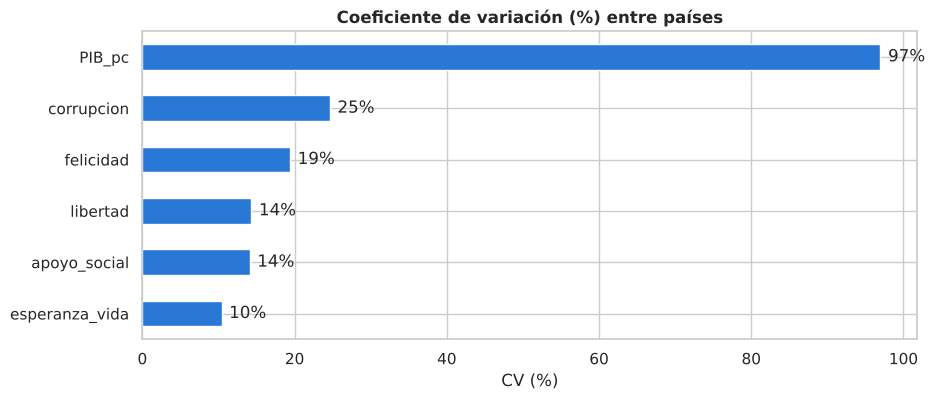

In [12]:
cv = (100 * df[cuantitativas].std() / df[cuantitativas].mean().abs()).drop(["generosidad", "log_PIB"]).sort_values()
ax = cv.plot.barh(color=AZUL)
ax.set_title("Coeficiente de variación (%) entre países"); ax.set_xlabel("CV (%)")
for i, v in enumerate(cv): ax.text(v + 1, i, f"{v:.0f}%", va="center")
plt.show()

🤔 `generosidad` la hemos quitado: su media es casi 0 (es un residuo, puede ser negativa). **¿Qué le pasa al CV cuando la media se acerca a 0?**

## 5. Medidas de forma: asimetría y curtosis
- Asimetría > 0 → cola a la **derecha**, normalmente media > mediana.
- Asimetría < 0 → cola a la **izquierda**, normalmente media < mediana.
- Curtosis (exceso) > 0 → colas más pesadas que la normal.

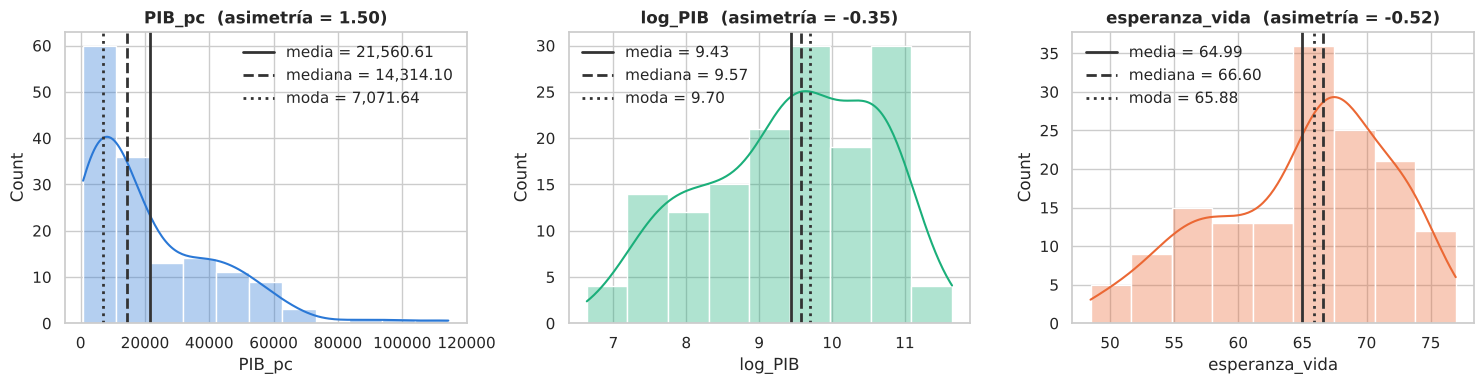

In [13]:
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
for ax, v, col in zip(axes, ["PIB_pc", "log_PIB", "esperanza_vida"], [AZUL, VERDE, NARANJA]):
    histograma_con_centros(df[v], f"{v}  (asimetría = {df[v].skew():.2f})", ax=ax, color=col)
plt.tight_layout(); plt.show()

🎯 **Fijaos en el truco del logaritmo:** el PIB per cápita es muy asimétrico a la derecha (pocos países muy ricos);
al tomar logaritmos la distribución se vuelve casi simétrica. Por eso los economistas trabajan con `log_PIB`.

## 6. Tabla resumen de TODAS las variables cuantitativas

In [14]:
tabla = df[cuantitativas].apply(resumen).T
tabla.style.format("{:,.2f}").background_gradient(subset=["asimetria_Fisher"], cmap="RdBu_r", vmin=-2, vmax=2)

,n,media,mediana,moda,media_recortada_5%,min,Q1,Q3,max,rango,RIC,varianza,desv_tipica,CV_%,MAD,asimetria_Fisher,asimetria_Pearson,curtosis_exceso,n_atipicos_Tukey
felicidad,149.00,5.53,5.53,5.18,5.54,2.52,4.85,6.25,7.84,5.32,1.40,1.15,1.07,19.41,0.70,-0.10,-0.00,-0.37,1.00
PIB_pc,149.00,"21,560.61","14,314.10","7,071.64","19,633.64",761.28,"5,120.46","33,556.97","114,347.80","113,586.53","28,436.51","437,177,275.79","20,908.78",96.98,"11,049.14",1.50,1.04,2.74,3.00
log_PIB,149.00,9.43,9.57,9.70,9.46,6.63,8.54,10.42,11.65,5.01,1.88,1.34,1.16,12.28,0.99,-0.35,-0.35,-0.82,0.00
apoyo_social,149.00,0.81,0.83,0.84,0.82,0.46,0.75,0.91,0.98,0.52,0.16,0.01,0.11,14.10,0.08,-0.94,-0.45,0.39,3.00
esperanza_vida,149.00,64.99,66.60,65.88,65.23,48.48,59.80,69.60,76.95,28.48,9.80,45.73,6.76,10.40,4.60,-0.52,-0.71,-0.56,0.00
libertad,149.00,0.79,0.80,0.87,0.80,0.38,0.72,0.88,0.97,0.59,0.16,0.01,0.11,14.32,0.08,-0.75,-0.33,0.41,1.00
generosidad,149.00,-0.02,-0.04,-0.06,-0.02,-0.29,-0.13,0.08,0.54,0.83,0.21,0.02,0.15,995.47,0.10,1.01,0.42,1.64,4.00
corrupcion,149.00,0.73,0.78,0.80,0.74,0.08,0.67,0.84,0.94,0.86,0.18,0.03,0.18,24.64,0.08,-1.58,-0.90,2.25,11.00


## 7. Datos anómalos (atípicos)
**Regla de Tukey** (la del diagrama de caja): es atípico todo lo que esté fuera de
$[Q_1 - 1.5\,RIC,\; Q_3 + 1.5\,RIC]$.

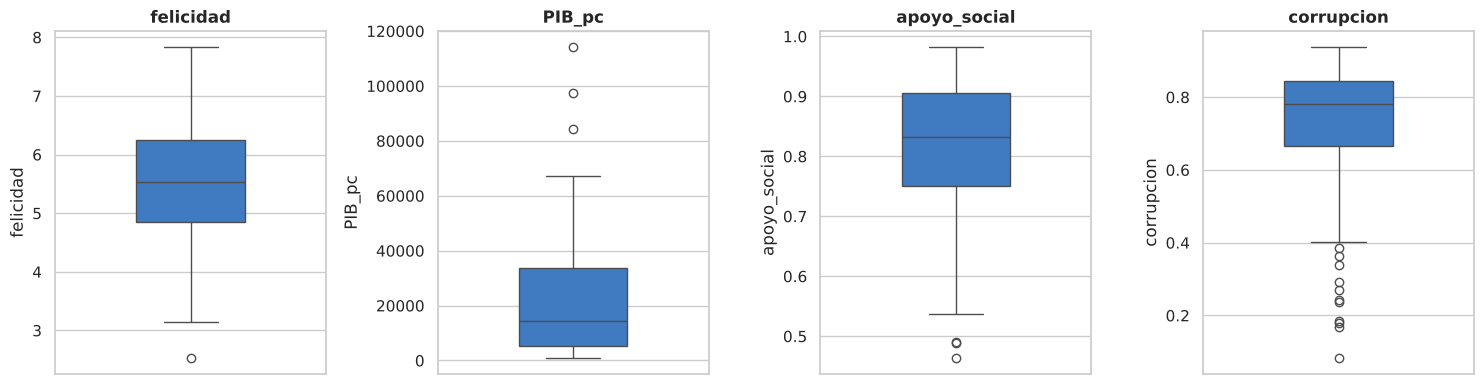

In [15]:
fig, axes = plt.subplots(1, 4, figsize=(15, 4))
for ax, v in zip(axes, ["felicidad", "PIB_pc", "apoyo_social", "corrupcion"]):
    sns.boxplot(y=df[v], ax=ax, color=AZUL, width=0.4, fliersize=6)
    ax.set_title(v)
plt.tight_layout(); plt.show()

In [16]:
for v in ["felicidad", "apoyo_social", "corrupcion", "esperanza_vida"]:
    li, ls = limites_tukey(df[v])
    at = df.loc[(df[v] < li) | (df[v] > ls), ["pais", "region", v]]
    print(f"\n--- {v}: vallas [{li:.2f}, {ls:.2f}] -> {len(at)} atípicos")
    print(at.to_string(index=False))


--- felicidad: vallas [2.75, 8.36] -> 1 atípicos
       pais     region  felicidad
Afghanistan South Asia      2.523

--- apoyo_social: vallas [0.52, 1.14] -> 3 atípicos
       pais             region  apoyo_social
      Benin Sub-Saharan Africa         0.489
    Burundi Sub-Saharan Africa         0.490
Afghanistan         South Asia         0.463

--- corrupcion: vallas [0.40, 1.11] -> 11 atípicos
       pais                region  corrupcion
    Finland        Western Europe       0.186
    Denmark        Western Europe       0.179
Switzerland        Western Europe       0.292
Netherlands        Western Europe       0.338
     Norway        Western Europe       0.270
     Sweden        Western Europe       0.237
 Luxembourg        Western Europe       0.386
New Zealand North America and ANZ       0.242
    Ireland        Western Europe       0.363
  Singapore        Southeast Asia       0.082
     Rwanda    Sub-Saharan Africa       0.167

--- esperanza_vida: vallas [45.11, 84.30] ->

🤔 Mirad `corrupcion`: los "atípicos" son los países nórdicos, Singapur… ¡con **muy poca** corrupción percibida!
Lo raro en el mundo es no tener corrupción.

Un atípico **no es un error**: Afganistán es realmente el país menos feliz del informe.
¿Qué haríais con él si quisierais describir a "un país típico"? ¿Lo quitaríais?

### Atípicos "relacionales": felicidad que no cuadra con la riqueza
Ajustamos una recta felicidad ~ log_PIB y miramos los países que más se alejan (residuos).

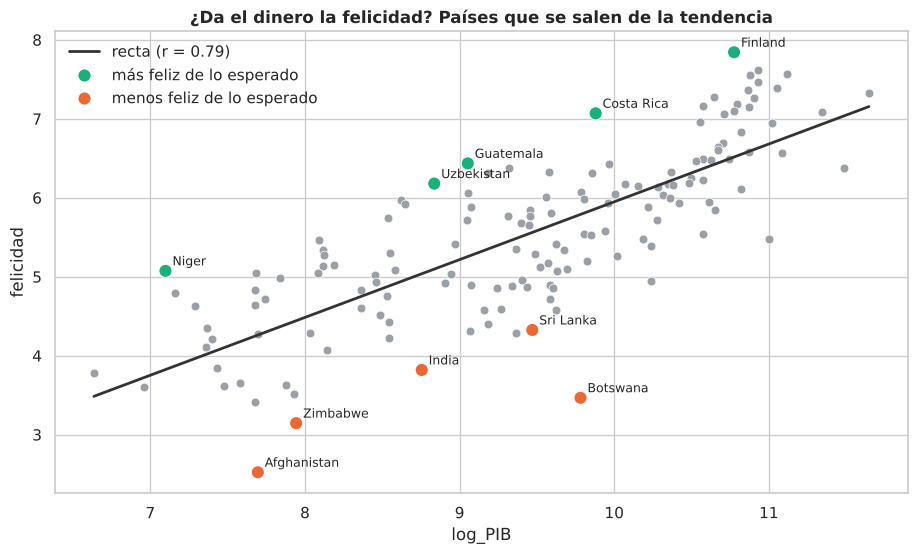

In [17]:
pend, ord_, r, *_ = stats.linregress(df["log_PIB"], df["felicidad"])
df["residuo"] = df["felicidad"] - (ord_ + pend * df["log_PIB"])

fig, ax = plt.subplots(figsize=(11, 6))
sns.scatterplot(data=df, x="log_PIB", y="felicidad", color="#9aa0a6", s=40, ax=ax)
xs = np.linspace(df["log_PIB"].min(), df["log_PIB"].max(), 50)
ax.plot(xs, ord_ + pend * xs, color="#333333", lw=2, label=f"recta (r = {r:.2f})")
extremos = pd.concat([df.nlargest(5, "residuo"), df.nsmallest(5, "residuo")])
sns.scatterplot(data=extremos, x="log_PIB", y="felicidad", hue=np.where(extremos["residuo"] > 0, "más feliz de lo esperado", "menos feliz de lo esperado"),
                palette=[VERDE, NARANJA], s=90, ax=ax)
for _, f in extremos.iterrows():
    ax.annotate(f["pais"], (f["log_PIB"], f["felicidad"]), xytext=(5, 4), textcoords="offset points", fontsize=9)
ax.set_title("¿Da el dinero la felicidad? Países que se salen de la tendencia")
ax.legend(frameon=False); plt.show()

## 8. 🏆 Comparación por grupos con `groupby`: ¿qué región es más feliz… y más desigual?

In [18]:
por_region = (df.groupby("region")["felicidad"]
                .agg(n="size", media="mean", mediana="median", desv="std",
                     minimo="min", maximo="max",
                     RIC=lambda s: s.quantile(.75) - s.quantile(.25))
                .assign(CV=lambda t: 100 * t["desv"] / t["media"])
                .sort_values("mediana", ascending=False))
por_region.style.format("{:.2f}").background_gradient(subset=["mediana"], cmap="Blues").background_gradient(subset=["CV"], cmap="Oranges")

,n,media,mediana,desv,minimo,maximo,RIC,CV
region,,,,,,,,
North America and ANZ,4.00,7.13,7.14,0.14,6.95,7.28,0.14,1.94
Western Europe,21.00,6.91,7.08,0.66,5.54,7.84,0.90,9.49
Central and Eastern Europe,17.00,5.98,6.08,0.49,5.10,6.96,0.44,8.24
Latin America and Caribbean,20.00,5.91,5.99,0.69,3.62,7.07,0.56,11.74
East Asia,6.00,5.81,5.76,0.44,5.34,6.58,0.39,7.57
Commonwealth of Independent States,12.00,5.47,5.47,0.44,4.88,6.18,0.60,8.01
Southeast Asia,9.00,5.41,5.38,0.61,4.43,6.38,0.85,11.21
South Asia,7.00,4.44,4.93,0.99,2.52,5.27,1.04,22.37
Middle East and North Africa,17.00,5.22,4.89,1.00,3.66,7.16,1.52,19.14


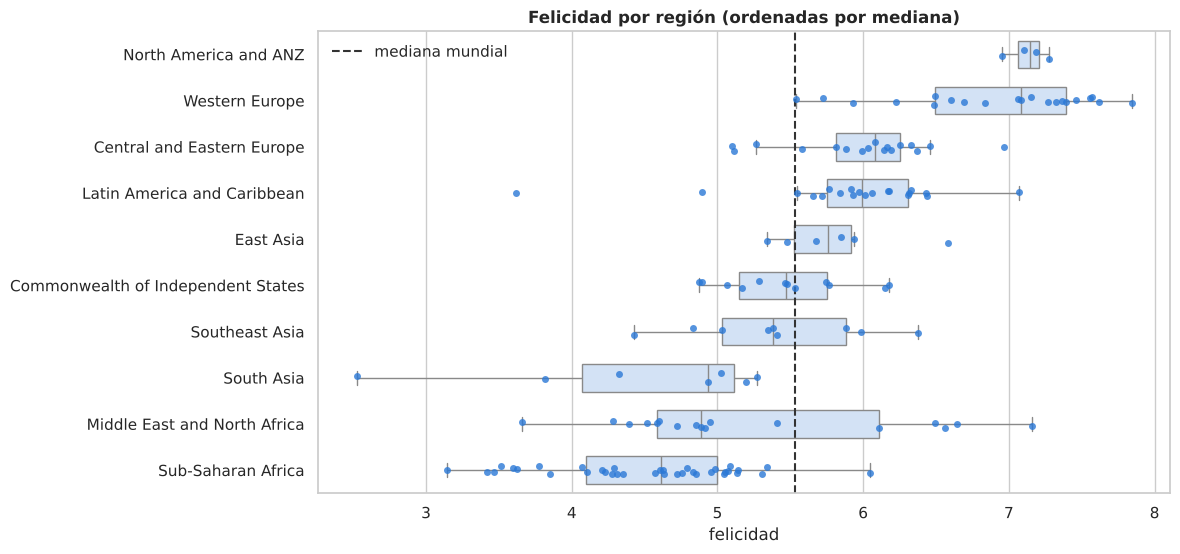

In [19]:
orden = por_region.index
fig, ax = plt.subplots(figsize=(11, 6))
sns.boxplot(data=df, y="region", x="felicidad", order=orden, color="#cde2fb", width=0.6, fliersize=0, ax=ax)
sns.stripplot(data=df, y="region", x="felicidad", order=orden, color=AZUL, size=5, alpha=0.8, ax=ax)
ax.axvline(df["felicidad"].median(), color="#333333", ls="--", lw=1.5, label="mediana mundial")
ax.set_title("Felicidad por región (ordenadas por mediana)"); ax.set_ylabel(""); ax.legend(frameon=False)
plt.show()

🤔 **Preguntas:**
1. ¿Qué región tiene la **mayor dispersión**? ¿Y la menor? (mira `RIC` y `CV`)
2. "North America and ANZ" solo tiene **4 países**. ¿Te fiarías de su media para compararla con África (36 países)?
3. ¿En qué región la media y la mediana se separan más? ¿Por qué?

### Perfil de cada región en todas las variables (tipificadas)
Tipificamos cada variable (z) para poder ponerlas en la misma escala y pintamos un mapa de calor.

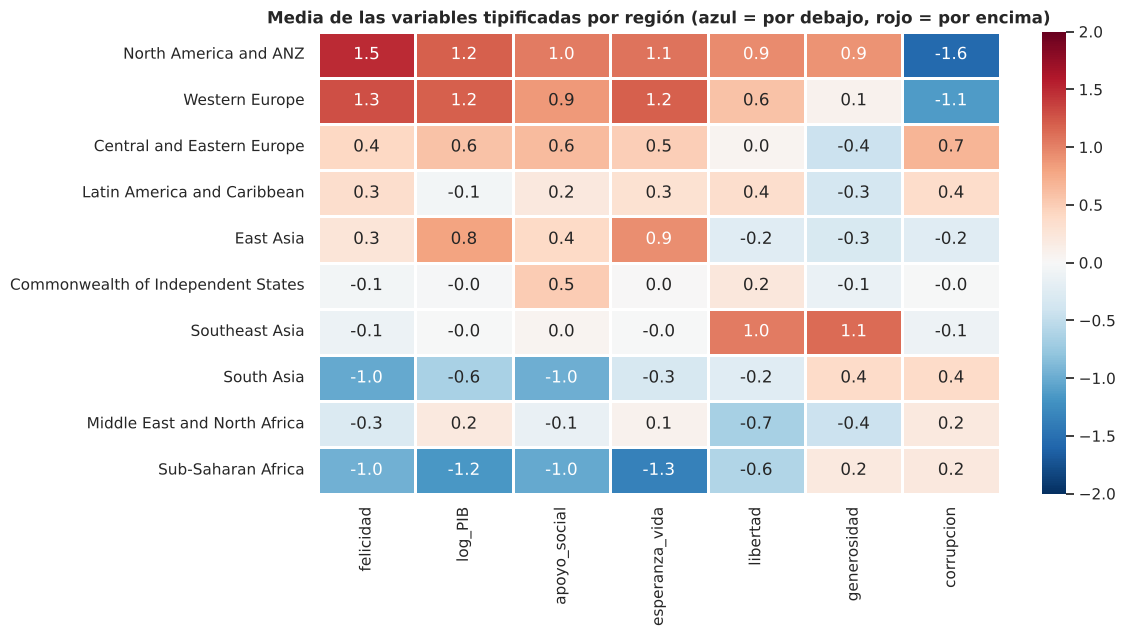

In [20]:
vars_perfil = ["felicidad", "log_PIB", "apoyo_social", "esperanza_vida", "libertad", "generosidad", "corrupcion"]
z = (df[vars_perfil] - df[vars_perfil].mean()) / df[vars_perfil].std()
perfil = z.groupby(df["region"]).mean().loc[orden]
plt.figure(figsize=(11, 6))
sns.heatmap(perfil, annot=True, fmt=".1f", cmap="RdBu_r", center=0, vmin=-2, vmax=2, linewidths=2, linecolor="white")
plt.title("Media de las variables tipificadas por región (azul = por debajo, rojo = por encima)")
plt.ylabel(""); plt.show()

### ⚠️ La media de los países NO es la media del mundo
Hemos tratado igual a India (1.400 millones) que a Islandia (370.000). La media de esta tabla es la del
"país típico", **no la de la persona típica**. Para eso necesitaríamos una **media ponderada** por población.

## 9. Dos variables a la vez: covarianza y correlación

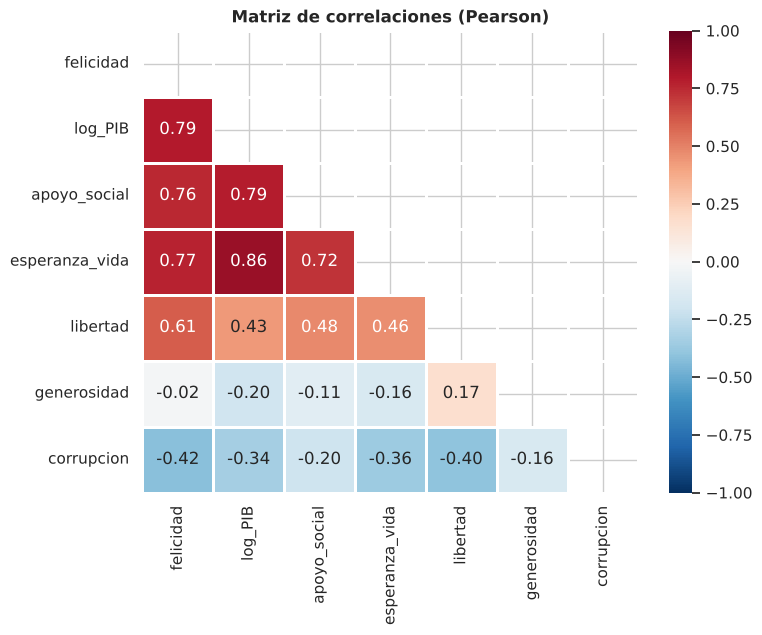

In [21]:
corr = df[vars_perfil].corr()
mask = np.triu(np.ones_like(corr, dtype=bool))
plt.figure(figsize=(8, 6))
sns.heatmap(corr, mask=mask, annot=True, fmt=".2f", cmap="RdBu_r", center=0, vmin=-1, vmax=1, linewidths=2, linecolor="white")
plt.title("Matriz de correlaciones (Pearson)"); plt.show()

In [22]:
print("Covarianza felicidad–esperanza_vida :", round(df["felicidad"].cov(df["esperanza_vida"]), 3))
print("Covarianza felicidad–log_PIB         :", round(df["felicidad"].cov(df["log_PIB"]), 3))
print("Correlación felicidad–esperanza_vida :", round(df["felicidad"].corr(df["esperanza_vida"]), 3))
print("Correlación felicidad–log_PIB        :", round(df["felicidad"].corr(df["log_PIB"]), 3))

Covarianza felicidad–esperanza_vida : 5.578
Covarianza felicidad–log_PIB         : 0.983
Correlación felicidad–esperanza_vida : 0.768
Correlación felicidad–log_PIB        : 0.79


🤔 La covarianza con esperanza de vida es mucho mayor que con log_PIB, pero la correlación es menor. **¿Por qué?**
(pista: unidades). Y recordad: **correlación no implica causalidad**.

## 10. ¿Se parece a una normal? Regla empírica vs. desigualdad de Chebyshev
- Normal: ~68 % de datos en $\bar x \pm s$, ~95 % en $\bar x \pm 2s$, ~99.7 % en $\bar x \pm 3s$.
- Chebyshev (vale para **cualquier** distribución): al menos $1 - 1/k^2$ en $\bar x \pm ks$.

In [23]:
def regla_empirica(x):
    x = pd.Series(x).dropna(); m, s = x.mean(), x.std()
    return pd.DataFrame({
        "k": [1, 2, 3],
        "observado_%": [100 * x.between(m - k*s, m + k*s).mean() for k in (1, 2, 3)],
        "normal_%": [68.27, 95.45, 99.73],
        "Chebyshev_min_%": [0, 75, 88.9],
    }).set_index("k")

print("Felicidad:"); print(regla_empirica(df["felicidad"]))
print("\nPIB per cápita (muy asimétrico):"); print(regla_empirica(df["PIB_pc"]))

Felicidad:
   observado_%  normal_%  Chebyshev_min_%
k                                        
1       69.128    68.270            0.000
2       97.987    95.450           75.000
3      100.000    99.730           88.900

PIB per cápita (muy asimétrico):
   observado_%  normal_%  Chebyshev_min_%
k                                        
1       83.221    68.270            0.000
2       96.644    95.450           75.000
3       97.987    99.730           88.900


## 🚀 Retos
1. Calcula la tabla de `resumen()` **por región** para `esperanza_vida`: `df.groupby("region")["esperanza_vida"].apply(resumen).unstack()`.
2. Crea una variable cualitativa ordinal `nivel_felicidad` con `pd.cut` (baja / media / alta) y haz una tabla de contingencia con `region` (`pd.crosstab(..., normalize="index")`).
3. ¿Qué país europeo es el más "anómalo" según su residuo? ¿Y el latinoamericano?
4. Repite el análisis de atípicos con z-scores ( |z| > 2.5 ). ¿Salen los mismos países que con Tukey?